In [11]:
from google.colab import files
uploaded = files.upload()

Saving star_classification.csv.zip to star_classification.csv (2).zip


In [12]:
import pandas as pd
df = pd.read_csv('star_classification.csv.zip')
print(df.shape)
print(df['class'].value_counts())
df.head()

(100000, 18)
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [13]:
df = df[(df[['u','g','r','i','z']]> -1000).all(axis=1)]
features = ['u','g','r','i','z','redshift']
X = df[features]
y = df['class']
print(X.isna().sum())

u           0
g           0
r           0
i           0
z           0
redshift    0
dtype: int64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 1. Fit Logistic Regression model
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)
print("Logistic Regression:", accuracy_score(y_test, lr.predict(X_test_s)))

# 2. Fit actual RandomForestClassifier model and evaluate with scaled test set
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_s, y_train)
print("Random Forest:", accuracy_score(y_test, rf.predict(X_test_s)))
print(classification_report(y_test, rf.predict(X_test_s)))

Logistic Regression: 0.9578
Random Forest: 0.97995
              precision    recall  f1-score   support

      GALAXY       0.98      0.99      0.98     11889
         QSO       0.97      0.93      0.95      3792
        STAR       1.00      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.98      0.97      0.98     20000
weighted avg       0.98      0.98      0.98     20000



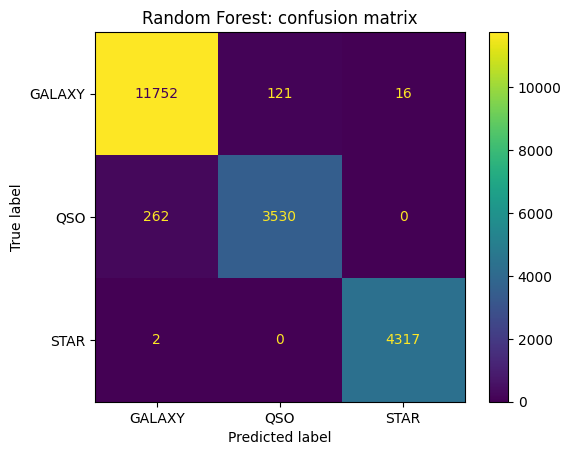

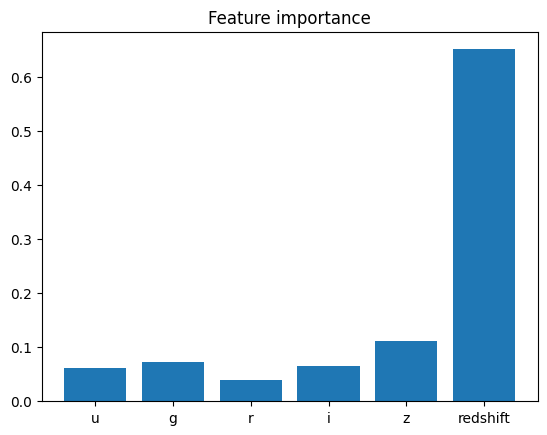

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(rf, X_test_s, y_test )
plt.title('Random Forest: confusion matrix')
plt.show()
plt.bar(X_train.columns, rf.feature_importances_)
plt.title('Random Forest: feature importance')
plt.title('Feature importance')
plt.show()

In [16]:
feat2 = ['u','g','r','i','z']
Xtr2, Xte2, ytr2, yte2 = train_test_split(
    df[feat2], df['class'], test_size=0.2, random_state=42, stratify=df['class'])
rf2 = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xtr2, ytr2)
print("Without redshift:", accuracy_score(yte2, rf2.predict(Xte2)))

Without redshift: 0.8742
